In [2]:
# import sys
from pathlib import Path

import torch
from torch import nn
import torch.nn.functional as F

import torchvision.transforms.v2 as v2

import matplotlib.pyplot as plt

# parent_dir = str(Path('../..').resolve())
# if parent_dir not in sys.path:
#     sys.path.append(parent_dir)
# from dmc_dataset.dataset import get_dataset


from rvsablation.ae import FSQ_VideoVAE
from rvsablation.core import _TransformerStack
from rvsablation.jepa import FSQ_V_JEPA
from rvsablation.utils import get_3d_sincos_pos_embed, read_config, seed_everything, get_dataset
rng = seed_everything(42)
from torchmetrics.image import StructuralSimilarityIndexMeasure

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_RUNS = {
    'ae': 'fsq_videovae_run_1', 
    'jepa': 'fsq_v_jepa_run_1',
}

SSIM = StructuralSimilarityIndexMeasure().to(DEVICE)

_, testset, _, _ = get_dataset(
    rng=rng,
    root='../data/walker_trajs_h5/data.h5',
    sample_num_frames=8,
    sample_num_clips=12,
    data_num_traj=25000,
    data_num_frames=100,
)

NUM_SAMPLES = 250

AE_VAR = torch.tensor([[[8.254, 7.391, 6.865, 2.122, 2.075, 2.111]]])
JEPA_VAR = torch.tensor([[[6.216, 6.483, 6.381, 1.902, 1.83, 1.91]]])

def draw_clip(x: torch.tensor):
    fig, axs = plt.subplots(1, 8, figsize=(20, 10))
    tpi = v2.ToPILImage()
    for i in range(x.shape[1]):
        axs[i].imshow(tpi(x[0, i]), vmin=0, vmax=255, cmap="grey")
        axs[i].axis("off")

    plt.show()

🌱 Global seed set to 42


In [3]:
class WindowTransitionProbe(nn.Module):
    def __init__(self, spatial_grid_size, temporal_grid_size, latent_dim, action_dim, hidden_dim, depth, attention_dim, attention_num_heads):
        super().__init__()
        self.latent_proj = nn.Linear(latent_dim, hidden_dim, bias=False)
        self.action_proj = nn.Linear(action_dim, hidden_dim, bias=False)
        self.out_proj = nn.Linear(hidden_dim, latent_dim, bias=False)
        self.stack = _TransformerStack(hidden_dim, depth, attention_dim, attention_num_heads)
        pos = get_3d_sincos_pos_embed(hidden_dim, temporal_grid_size, spatial_grid_size)
        self.register_buffer('pos', pos.unsqueeze(0), persistent=False)

    def forward(self, x, action):
        x = self.latent_proj(x)
        action = self.action_proj(action).unsqueeze(1)
        return self.out_proj(self.stack(x + action + self.pos, attn_mask=None))

# Visual Perturbation Studies

In [4]:
def load_model_pair(model_type: str, run_name, sample_actions):
    run_dir = Path("..") / f'{model_type}_runs' / run_name

    model_config = read_config(run_dir / 'confs' / 'model_config.json')

    encoder_class = FSQ_VideoVAE if model_type == "ae" else FSQ_V_JEPA
    encoder = encoder_class(**model_config)
    encoder.load_state_dict(torch.load(run_dir / 'weights' / 'model_4.9m.pt', map_location=DEVICE, weights_only=True))
    encoder = encoder.to(DEVICE).eval()

    transition_model = WindowTransitionProbe(
        spatial_grid_size=encoder.encoder.spatial_grid_size,
        temporal_grid_size=encoder.encoder.temporal_grid_size,
        latent_dim=model_config["fsq_dim"],
        action_dim=sample_actions.shape[-1],
        hidden_dim=384, depth=6, attention_dim=384, attention_num_heads=6,
    ).to(DEVICE)
    transition_model.load_state_dict(torch.load(run_dir / 'transition_window' / 'transition_window_best.pt', map_location=DEVICE, weights_only=True))

    var = AE_VAR if model_type == "ae" else JEPA_VAR

    return encoder, transition_model, var.to(DEVICE)

fs, sample_actions, *_ = testset[0]

model_pairs = {
    model_type: load_model_pair(model_type, run_name, sample_actions) # sample actions is only used to get the dimension of the actions
    for model_type, run_name in MODEL_RUNS.items()
}

In [5]:
PERTURBATION_A = v2.Compose([
    v2.GaussianBlur(11, sigma=(0.01, 1)),
    # T.ColorJitter(hue=(0, 0.3))
])
def perturb_clip(x: torch.tensor, perturbation: v2.Compose, sigma: float):
    epsilon = torch.randn_like(x) * sigma
    return perturbation((epsilon + x).clamp(0, 1))

torch.Size([1, 8, 3, 84, 84]) torch.Size([1, 8, 3, 84, 84])


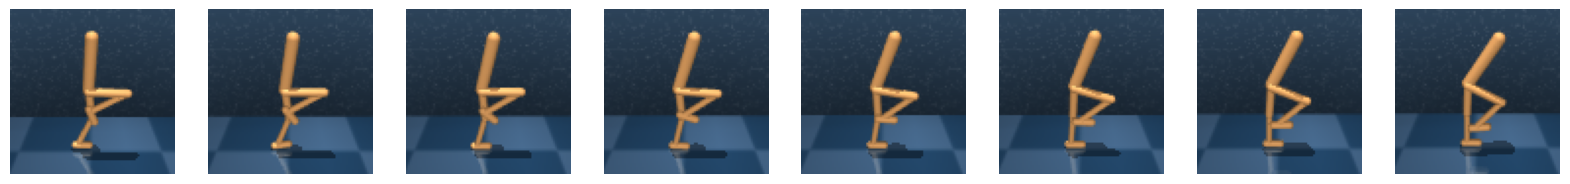

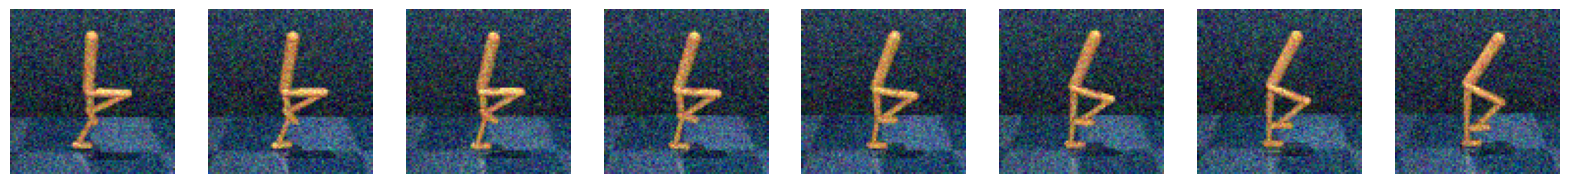

In [6]:
SIG = 0.1
uf = fs[None]
pf = perturb_clip(fs[None], PERTURBATION_A, SIG)
print(uf.shape, pf.shape)
draw_clip(uf)
draw_clip(pf)

In [7]:
@torch.no_grad()
def perturbation_probe(model: FSQ_V_JEPA | FSQ_VideoVAE, transition: WindowTransitionProbe, unperturbed, perturbed, action, variance):
    embedding = model(unperturbed)
    perturbed_embedding = model(perturbed)

    trans = model.quantizer.f(transition(embedding, action)).round()
    perturbed_trans = model.quantizer.f(transition(perturbed_embedding, action)).round()

    changed = (embedding != perturbed_embedding).any(dim=-1)
    changed_transitions = (trans != perturbed_trans).any(dim=-1)

    N = changed.shape[-1]

    changed_perc = changed.float().mean()
    changed_transitions_perc = changed_transitions.float().mean()

    static_dist = F.l1_loss(embedding[changed], perturbed_embedding[changed], reduction="none") / (variance ** 0.5)
    transition_dist = F.l1_loss(trans[changed_transitions], perturbed_trans[changed_transitions], reduction="none") / (variance ** 0.5)

    ssim = SSIM(unperturbed[0], perturbed[0])

    return changed_perc, static_dist.mean(dim=(-1, -2)), changed_transitions_perc, transition_dist.mean(dim=(-1, -2)), ssim


probe_results = {}
ssims = []
for i in range(NUM_SAMPLES):
    frames, actions, *_ = testset[i]

    frames = frames[None].to(DEVICE)
    perturbed_frames = perturb_clip(frames, PERTURBATION_A, SIG).to(DEVICE)
    action = actions[-1][None].to(DEVICE, dtype=torch.float32)

    for name, (model, transition, variance) in model_pairs.items():

        changed_perc, static_dist, changed_transition_perc, transition_dist, ssim = perturbation_probe(model, transition, frames, perturbed_frames, action, variance)

        if name not in probe_results:
            probe_results[name] = {
                "changed": [],
                "static_dist": [],
                "changed_transition_perc": [],
                "transition_dist": []
            }

        ssims.append(ssim)
        probe_results[name]["changed"].append(changed_perc)
        probe_results[name]["static_dist"].append(static_dist)
        probe_results[name]["changed_transition_perc"].append(changed_transition_perc)
        probe_results[name]["transition_dist"].append(transition_dist)
    
ssims = torch.stack(ssims).mean().item()
print(f"Avg. SSIM={ssims:.2f}")
for name, *_ in model_pairs.items():
    changed = torch.stack(probe_results[name]["changed"]).mean()
    static_dist = torch.stack(probe_results[name]["static_dist"]).mean()
    changed_transition_perc = torch.stack(probe_results[name]["changed_transition_perc"]).mean()
    transition_dist = torch.stack(probe_results[name]["transition_dist"]).mean()

    print(f"{name}")
    print(f"\t changed={changed:.2f} \t static_dist={static_dist:.2f} \t changed_transition_perc={changed_transition_perc:.2f} \t transition_dist={transition_dist:.2f}")

Avg. SSIM=0.43
ae
	 changed=0.97 	 static_dist=0.39 	 changed_transition_perc=0.86 	 transition_dist=0.43
jepa
	 changed=0.89 	 static_dist=0.25 	 changed_transition_perc=0.74 	 transition_dist=0.27
